# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
180,-0.038207,0.050680,0.004572,0.035644,-0.011201,0.005889,-0.047082,0.034309,0.016307,-0.001078,107.0
191,-0.005515,0.050680,-0.041774,-0.043542,-0.079998,-0.076156,-0.032356,-0.039493,0.010227,-0.009362,178.0
381,-0.070900,0.050680,-0.089197,-0.074527,-0.042848,-0.025739,-0.032356,-0.002592,-0.012909,-0.054925,104.0
71,-0.001882,-0.044642,0.033673,0.125158,0.024574,0.026243,-0.010266,-0.002592,0.026717,0.061054,270.0
12,0.016281,-0.044642,-0.028840,-0.009113,-0.004321,-0.009769,0.044958,-0.039493,-0.030748,-0.042499,179.0
135,-0.005515,-0.044642,0.056307,-0.036656,-0.048351,-0.042963,-0.072854,0.037999,0.050782,0.056912,272.0
56,-0.041840,-0.044642,0.041218,-0.026328,-0.031840,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0
337,0.019913,0.050680,-0.012673,0.070072,-0.011201,0.007141,-0.039719,0.034309,0.005386,0.003064,91.0
154,0.067136,0.050680,0.020739,-0.005670,0.020446,0.026243,-0.002903,-0.002592,0.008641,0.003064,197.0
267,0.059871,-0.044642,-0.000817,-0.084856,0.075484,0.079478,0.004460,0.034309,0.023371,0.027917,115.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

Se introducen valores nulos de manera aleatoria en el 10% del conjunto para simular información faltante

.index: Extrae únicamente los identificadores (los números o etiquetas de fila) de esa muestra del 10%.

data.loc[..., 'bmi'] = np.nan: Utiliza loc para acceder a esas filas específicas pero limitándose a la columna bmi (bmi es la columna seleccionada), y asigna a todas esas celdas el valor np.nan (Not a Number, la representación de un valor nulo en Pandas/NumPy).

'bp' es otra columna a la que se intruduciran de manera aleatoria valores nulos, completamente independiente a 'bmi', no seran las mismas filas donde falten ambos datos

In [5]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
385,0.023546,0.050680,-0.019140,0.049415,-0.063487,-0.061125,0.004460,-0.039493,-0.025953,-0.013504,219.0
300,0.016281,-0.044642,0.073552,NaN,-0.004321,-0.013527,-0.013948,-0.001116,0.042897,0.044485,275.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
42,-0.060003,0.050680,-0.010517,-0.014863,-0.049727,-0.023547,-0.058127,0.015858,-0.009919,-0.034215,61.0
311,0.096197,-0.044642,NaN,-0.057313,0.045213,0.060690,-0.021311,0.036154,0.012551,0.023775,180.0
200,0.056239,-0.044642,-0.057941,-0.007977,0.052093,0.049103,0.056003,-0.021412,-0.028323,0.044485,158.0
271,0.038076,0.050680,0.008883,0.042529,-0.042848,-0.021042,-0.039719,-0.002592,-0.018114,0.007207,127.0
76,-0.030942,0.050680,NaN,0.070072,-0.126781,-0.106845,-0.054446,-0.047981,-0.030748,0.015491,170.0


# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [6]:
#hay 44 valores faltantes en la columna 'bmi' y 44 valores faltantes en la columna 'bp'
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [7]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean')
datos_imputados = imputer.fit_transform(data[['bmi', 'bp']])

imputer: que estrategia usara para rellenar espacios vacios

imputer.fit(datos): Escanea la columna y calcula el promedio matemático de los números que sí existen en cada columna.
Guarda esos promedios en su memoria interna (en un atributo que puedes consultar llamado imputer.statistics_).

imputer.transform(datos): el algoritmo toma acción volviendo a recorrer tus datos.
Cada vez que choca con un NaN, busca en su memoria qué promedio calculó para esa columna específica en el paso anterior y lo inserta ahí.

Usamos imputer.fit_transform para hacerlo al mismo tiempo y hacer mas rapido el proceso

In [8]:
#Ver los valores que usara como media
imputer.statistics_

array([-0.00020487,  0.00046538])

Metodo 1: Un nuevo DataFrame

In [9]:
# crea una copia del DataFrame original y actualiza las columnas imputadas
datos_limpios = data.copy()
datos_limpios[['bmi', 'bp']] = datos_imputados


display(datos_limpios.head()) 

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,0.000465,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
#comprobamos que ya no hay valores faltantes
datos_limpios.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [11]:
# Inicializar el imputador KNN con 2 vecinos
knn_imputer = KNNImputer(n_neighbors=2)

# Aplicar el imputador a los datos
df_imputed = pd.DataFrame(knn_imputer.fit_transform(data), columns=data.columns)

# Mostrar los datos con valores imputados
print(df_imputed)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.043542 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906 -0.028049 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  target  
0   -0.002592  0.019907 -0.0176

In [12]:
#Crea la copia para proteger los datos originales
datos_limpiosKNN = data.copy()

#Transfiere únicamente las dos columnas del dataset imputado al nuevo dataset
datos_limpiosKNN[['bmi', 'bp']] = df_imputed[['bmi', 'bp']]

# Compruebas el resultado
display(datos_limpiosKNN.head())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.043542,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [13]:
#comprobamos que ya no hay valores faltantes
datos_limpiosKNN.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

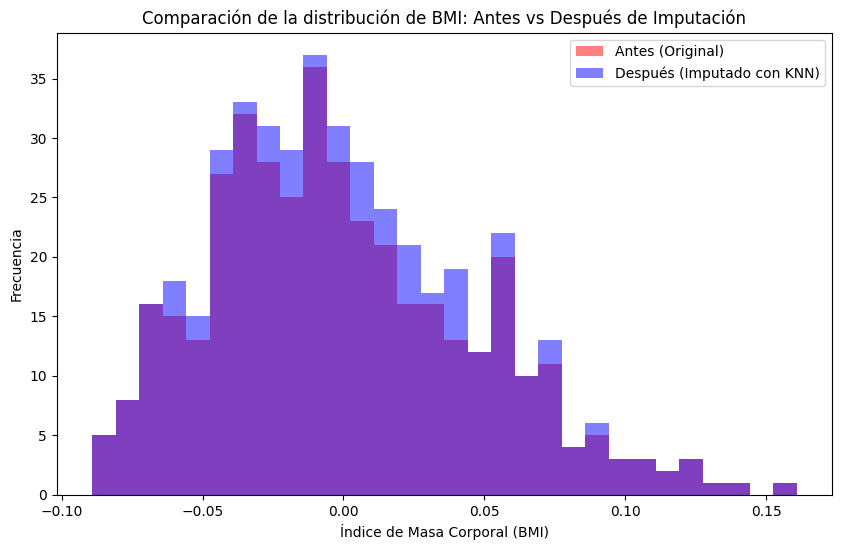

In [17]:
import matplotlib.pyplot as plt

# Ajustar el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Histograma ANTES de la imputación (Original)
# .dropna() ignora los valores nulos al graficar
plt.hist(data['bmi'].dropna(), bins=30, alpha=0.5, color='red', label='Antes (Original)')

# Histograma DESPUÉS de la imputación (KNN)
plt.hist(datos_limpiosKNN['bmi'], bins=30, alpha=0.5, color='blue', label='Después (Imputado con KNN)')


plt.title('Comparación de la distribución de BMI: Antes vs Después de Imputación')
plt.xlabel('Índice de Masa Corporal (BMI)')
plt.ylabel('Frecuencia')

# Mostrar las leyendas para identificar cada color
plt.legend()

# Mostrar el gráfico
plt.show()